In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dls.linear_regression import train, predict
from dls.dataset import boston_train_test_split
from dls.model_error import mae, rmse


In [2]:
boston_ns = boston_train_test_split()
X_train, y_train, X_test, y_test, features = (
    boston_ns.X_train,
    boston_ns.y_train,
    boston_ns.X_test,
    boston_ns.y_test,
    boston_ns.features,
)

In [3]:
train_info = train(
    X_train,
    y_train,
    n_iter=1000,
    learning_rate=0.001,
    batch_size=23,
    return_losses=True,
    return_weights=True,
    seed=180708,
)
losses = train_info[0]
weights = train_info[1]


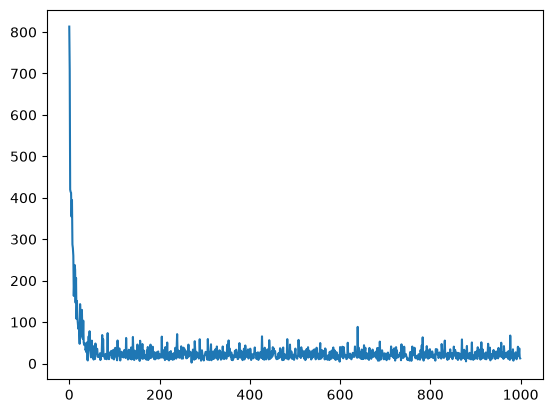

In [4]:
plt.plot(list(range(1000)), losses)

In [7]:
preds = predict(X_test, weights)
print(
    "Mean absolute error:",
    round(mae(preds, y_test), 4),
    "\nRoot mean squared error:",
    round(rmse(preds, y_test), 4),
)

Mean absolute error: 3.5644 
Root mean squared error: 5.0497


In [8]:
NUM = 40
a = np.repeat(X_test[:, :-1].mean(axis=0, keepdims=True), NUM, axis=0)
b = np.linspace(-1.5, 3.5, NUM).reshape(NUM, 1)
test_feature = np.concatenate([a, b], axis=1)
preds_test = predict(test_feature, weights)[:, 0]


Text(0.5, 1.0, 'Most important feature vs. target and predictions,\n neural network regression')

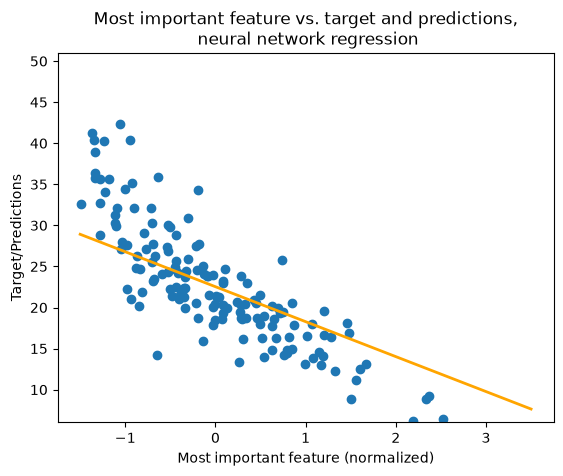

In [9]:
plt.scatter(X_test[:, 12], preds)
plt.plot(np.array(test_feature[:, -1]), preds_test, linewidth=2, c="orange")
plt.ylim([6, 51])
plt.xlabel("Most important feature (normalized)")
plt.ylabel("Target/Predictions")
plt.title(
    "Most important feature vs. target and predictions,\n neural network regression"
)
